In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("data.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.drop(['customerID'],axis=1,inplace=True)

In [11]:
df.shape

(7043, 20)

In [12]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

In [13]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in df.select_dtypes(include=['object','string']).columns:
    
    df[col]=le.fit_transform(df[col])

In [14]:
df.groupby(['gender','Churn']).size()

gender  Churn
0       0        2549
        1         939
1       0        2625
        1         930
dtype: int64

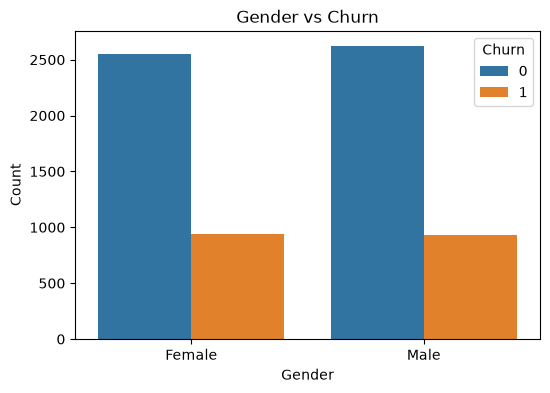

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

sns.countplot(data=df, x='gender', hue='Churn')

plt.title("Gender vs Churn")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.xticks([0, 1], ['Female', 'Male'])
plt.legend(title="Churn")

plt.show()

In [16]:
df.groupby(['SeniorCitizen','Churn']).size()

SeniorCitizen  Churn
0              0        4508
               1        1393
1              0         666
               1         476
dtype: int64

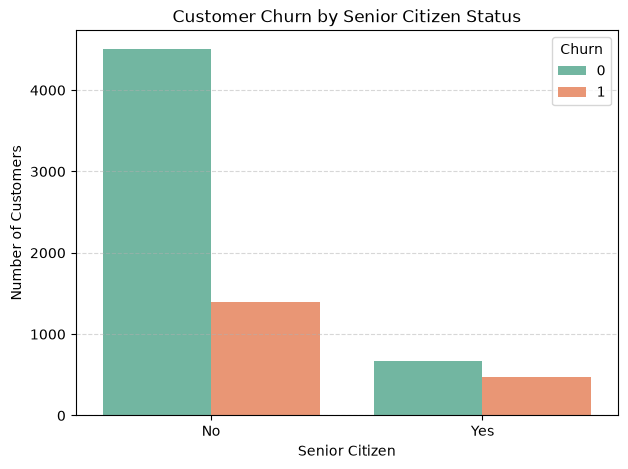

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='SeniorCitizen',
    hue='Churn',
    palette='Set2'
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ['No', 'Yes'])   
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [18]:
df['Total_services']=(df.loc[:,'PhoneService':'StreamingMovies']).sum(axis=1)

In [19]:
df.groupby(['Total_services','Churn']).size().unstack(fill_value=0)


Churn,0,1
Total_services,,
1,145,105
2,95,138
3,251,134
4,176,255
5,345,94
6,251,267
7,357,65
8,315,241
9,1414,138


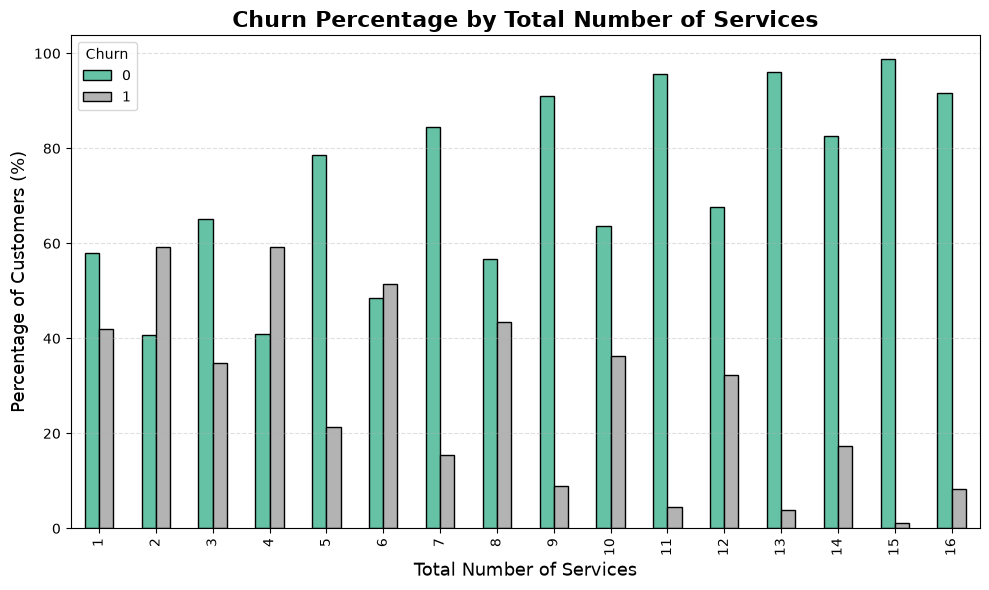

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

churn_rate = (
    pd.crosstab(df['Total_services'], df['Churn'], normalize='index') * 100
)

churn_rate.plot(
    kind='bar',
    figsize=(10,6),
    colormap='Set2',
    edgecolor='black'
)

plt.title('Churn Percentage by Total Number of Services', fontsize=16, fontweight='bold')
plt.xlabel('Total Number of Services', fontsize=13)
plt.ylabel('Percentage of Customers (%)', fontsize=13)

plt.legend(title='Churn')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [21]:
df['AvgMonthlyCharge'] = df['TotalCharges'] / df['tenure']


df['AvgMonthlyCharge'] = np.where(
    df['tenure'] == 0,
    0,
    df['TotalCharges'] / df['tenure']
)

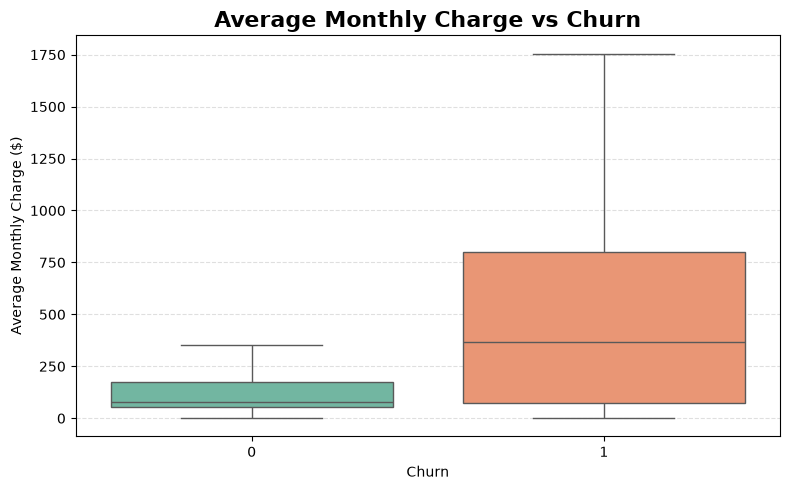

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Churn',
    y='AvgMonthlyCharge',
    hue='Churn',
    palette='Set2',
    legend=False,
    showfliers=False
)

plt.title('Average Monthly Charge vs Churn', fontsize=16, fontweight='bold')
plt.xlabel('Churn')
plt.ylabel('Average Monthly Charge ($)')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [23]:
df['ChargePerService'] = np.where(
    df['Total_services'] == 0,
    0,
    df['MonthlyCharges'] / df['Total_services']
)

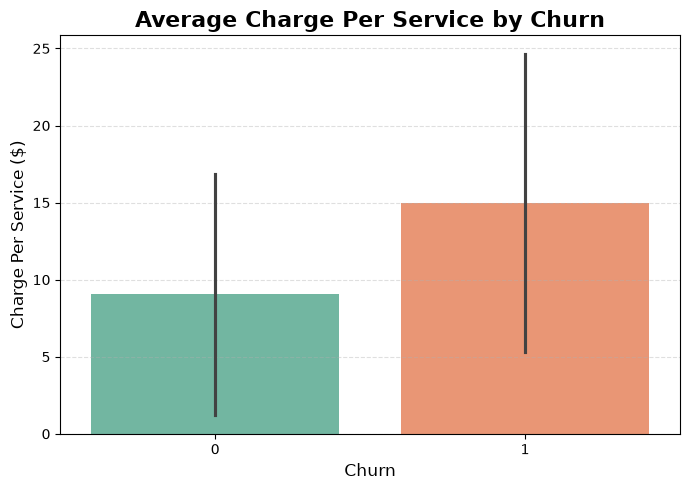

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.barplot(
    data=df,
    x='Churn',
    y='ChargePerService',
    hue='Churn',
    palette='Set2',
    legend=False,
    errorbar='sd'
)

plt.title('Average Charge Per Service by Churn', fontsize=16, fontweight='bold')
plt.xlabel('Churn', fontsize=12)
plt.ylabel('Charge Per Service ($)', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [25]:
df['CustomerValue'] = df['MonthlyCharges'] * df['Total_services']

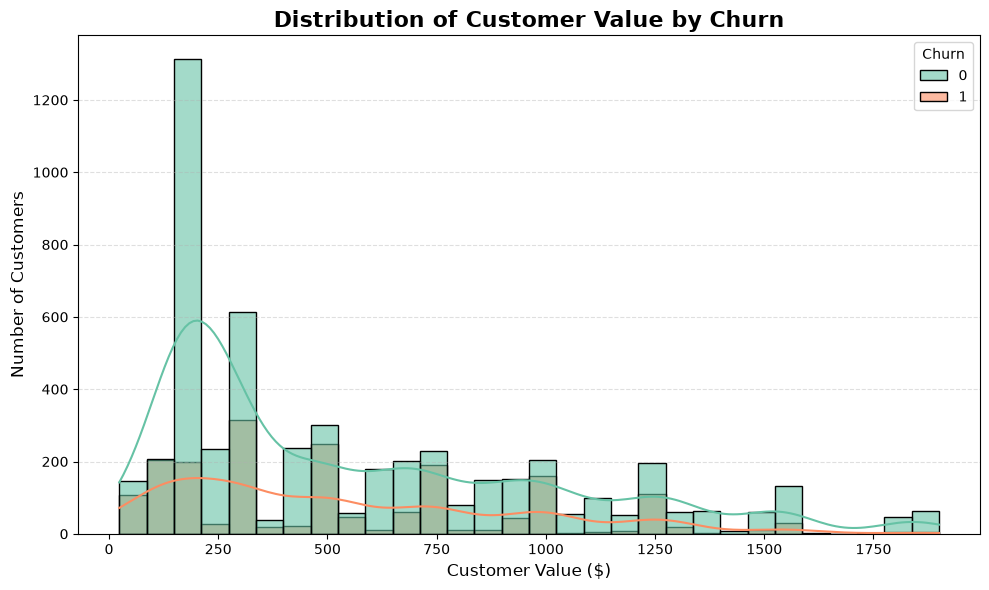

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x='CustomerValue',
    hue='Churn',
    bins=30,
    kde=True,
    palette='Set2',
    alpha=0.6
)

plt.title('Distribution of Customer Value by Churn', fontsize=16, fontweight='bold')
plt.xlabel('Customer Value ($)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [27]:
df.groupby(['Contract','Churn']).size().unstack(fill_value=0)


Churn,0,1
Contract,,
0,2220,1655
1,1307,166
2,1647,48


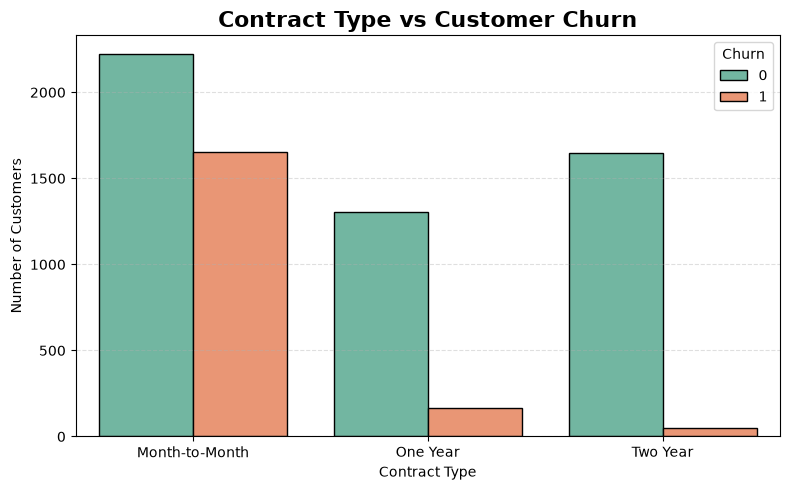

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x='Contract',
    hue='Churn',
    palette='Set2',
    edgecolor='black'
)

# Set both tick positions and labels
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Month-to-Month', 'One Year', 'Two Year'])

plt.title('Contract Type vs Customer Churn', fontsize=16, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [29]:
X = df.drop(columns=['Churn'])
y = df['Churn']

In [30]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=11)

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()    

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2

In [33]:
model1= Sequential([
    Dense(units=32,activation='relu',kernel_regularizer= l2(0.001)),
           Dense(16,activation='relu',kernel_regularizer= l2(0.001)),
             Dense(8,activation='relu',kernel_regularizer= l2(0.001)),
            Dense(1,activation='sigmoid')])
model1.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
history=model1.fit(X_train,y_train,epochs=100,batch_size=32,validation_data=(X,y))


Epoch 1/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6480 - loss: 4.9274 - val_accuracy: 0.7617 - val_loss: 1.5958
Epoch 2/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7183 - loss: 1.3858 - val_accuracy: 0.7581 - val_loss: 1.6384
Epoch 3/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7322 - loss: 1.2847 - val_accuracy: 0.7748 - val_loss: 0.8094
Epoch 4/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7501 - loss: 0.9505 - val_accuracy: 0.3557 - val_loss: 4.4928
Epoch 5/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7352 - loss: 1.3393 - val_accuracy: 0.7608 - val_loss: 0.8790
Epoch 6/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7398 - loss: 0.8259 - val_accuracy: 0.6284 - val_loss: 0.9715
Epoch 7/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7460 - loss: 0.9140 - val_accuracy: 0.6662 - val_loss: 1.0011
Epoch 8/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7540 - loss: 0.8051 - val_acc

In [34]:
loss, accuracy=model1.evaluate(X_test,y_test)
print("Test loss: ",loss)
print("Test accuracy: ",accuracy)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7857 - loss: 0.4591
Test loss:  0.4591113030910492
Test accuracy:  0.7856636047363281


In [35]:
loss,accuracy=model1.evaluate(X_train,y_train)
print("loss: ",loss)
print("accuracy: ",accuracy)

177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7863 - loss: 0.4631
loss:  0.46310344338417053
accuracy:  0.7862975001335144


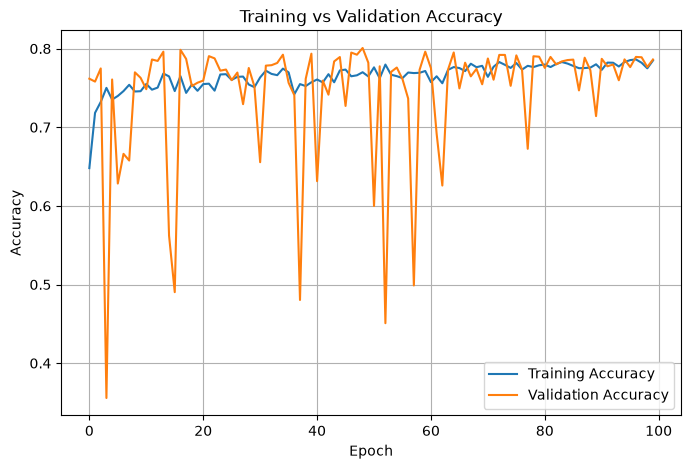

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

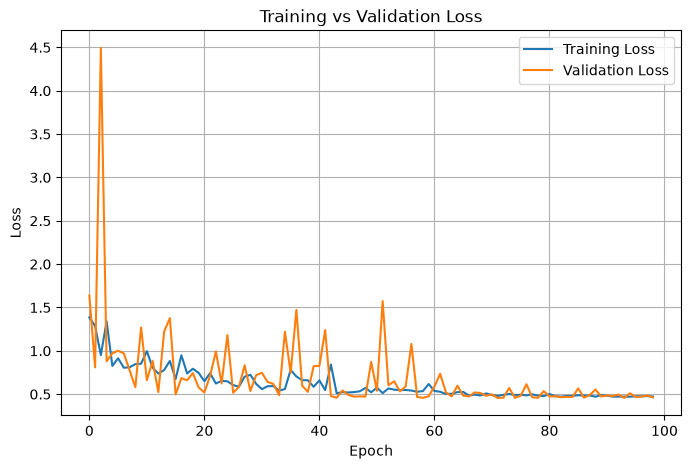

In [37]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'][1:], label='Training Loss')
plt.plot(history.history['val_loss'][1:], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
y_pred=model1.predict(X_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [39]:
y_pred=(y_pred>0.5).astype(int)

In [40]:
from sklearn.metrics import classification_report
cr=classification_report(y_test,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.79      0.96      0.87      1031
           1       0.73      0.32      0.45       378

    accuracy                           0.79      1409
   macro avg       0.76      0.64      0.66      1409
weighted avg       0.78      0.79      0.75      1409



In [41]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[985  46]
 [256 122]]


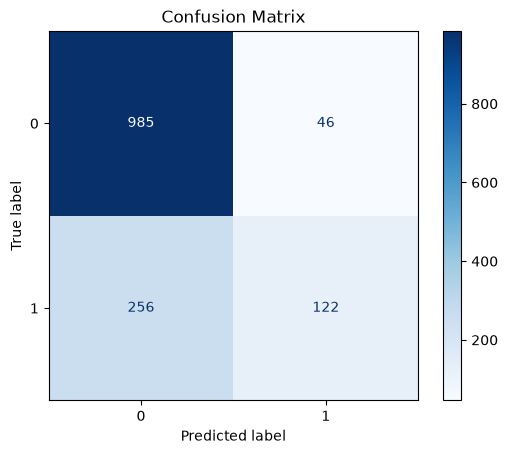

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=8,
    min_samples_split=15,
    min_samples_leaf=8,
    max_features='sqrt',
    bootstrap=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)


train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)


print("\nClassification Report")
print(classification_report(y_test, y_test_pred))


print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_test_pred))

Training Accuracy: 0.7933972310969116
Testing Accuracy: 0.7629524485450674

Classification Report
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1031
           1       0.54      0.79      0.64       378

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409


Confusion Matrix
[[775 256]
 [ 78 300]]


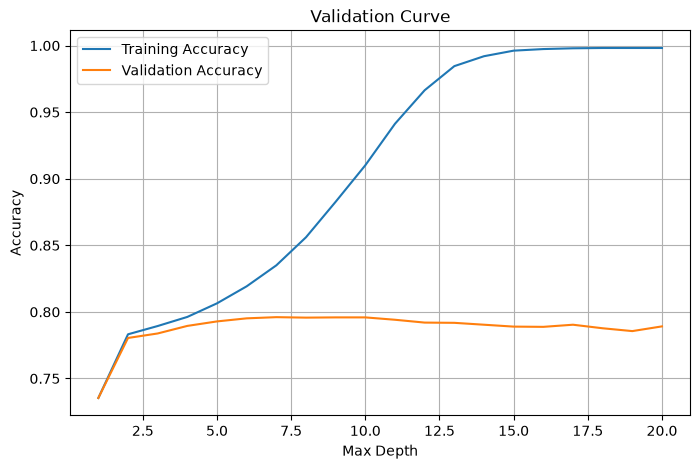

In [44]:
from sklearn.model_selection import validation_curve
import numpy as np
import matplotlib.pyplot as plt

param_range = np.arange(1, 21)

train_scores, test_scores = validation_curve(
    RandomForestClassifier(random_state=42),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure(figsize=(8,5))
plt.plot(param_range, train_mean, label="Training Accuracy")
plt.plot(param_range, test_mean, label="Validation Accuracy")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Validation Curve")
plt.legend()
plt.grid(True)
plt.show()

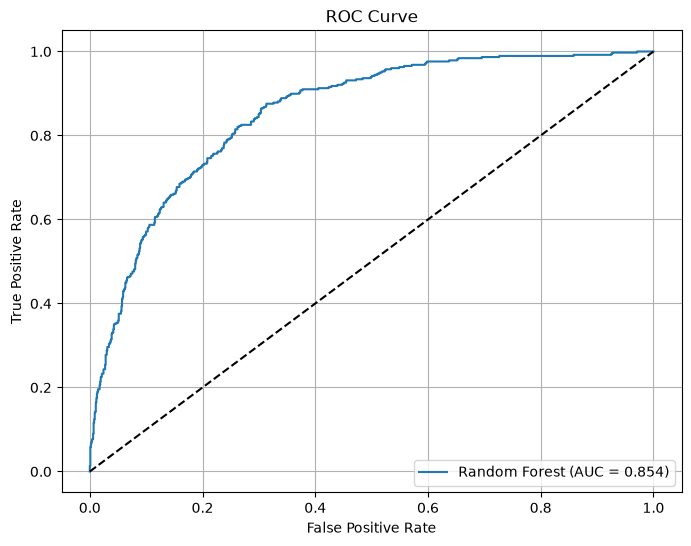

In [45]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


y_prob = rf.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()